# Stochastic Processes

A **stochastic process** is a mathematical model used to describe the evolution over time of a system whose state is subject to random variations. 
Examples of stochastic processes are:

- <u>Stock price movement</u>: the price of a stock varies over time unpredictably, influenced by factors such as supply and demand, economic news, and investor decisions
- <u>Trajectory of a particle in a fluid</u>: a particle suspended in a fluid moves randomly due to collisions with fluid molecules
- <u>Number of customers in a queue</u>: the number of customers waiting in a queue varies over time depending on the arrival of new customers and the service rate

There are several classifications of stochastic processes, based on different characteristics:

- Discrete time vs. continuous time: depending on whether time is measured in discrete or continuous intervals
- Discrete state space vs. continuous state space: depending on whether the system can assume a finite or infinite number of states
- Markovian processes vs. non-Markovian processes: depending on whether the future of the system depends only on the present state (Markovian) or also on the past (non-Markovian)

## Gaussian Process

A notable case of stochastic process is the **Gaussian stochastic process**, where any finite collection of the random variables involved in the process has a multivariate normal distribution. This means that if you take any set of $n$ random variables from the process, their joint probability distribution will be a Gaussian (or normal) distribution. This process is non-Markovian, since its behavior is completely determined by its mean function and covariance.

Key properties of Gaussian stochastic processes are:

- <u>Normality</u>: as mentioned above, the defining characteristic is that all finite combinations of the random variables are normally distributed
- <u>Complete specification by mean and standard deviation</u>: a Gaussian process is fully defined by its mean and standard deviation 

A fundamental Gaussian process, from which many other stationary processes may be derived, is the so-called **white noise process** which consists of a sequence of uncorrelated random variables, each with a zero mean and the same finite variance.

The most simple model for the Gaussian process doesn't involve time, so its *bias model* (the statistical description of the measurement errors) is just described by the following parameters:

- 1-$\sigma$ value. It describes how sparse are the data around the mean
- Sistematic error: non-normally distributed error 
- White noise: the value of the underlying noise 

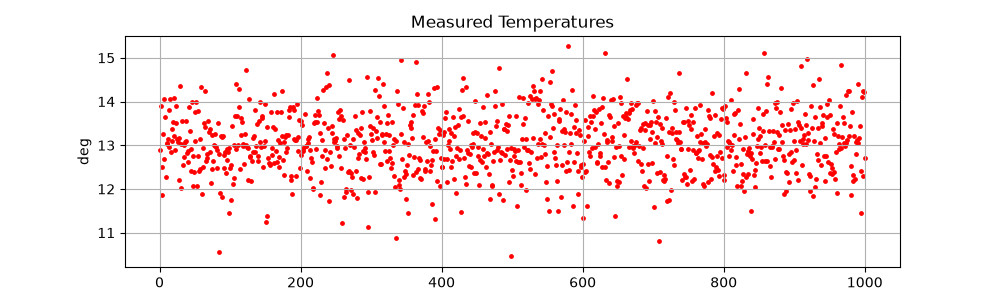

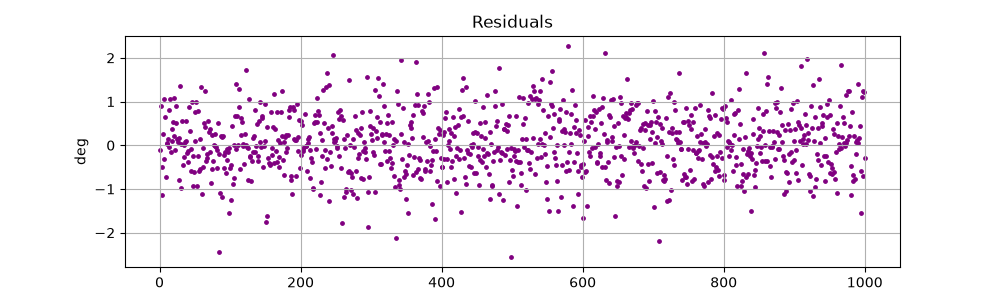

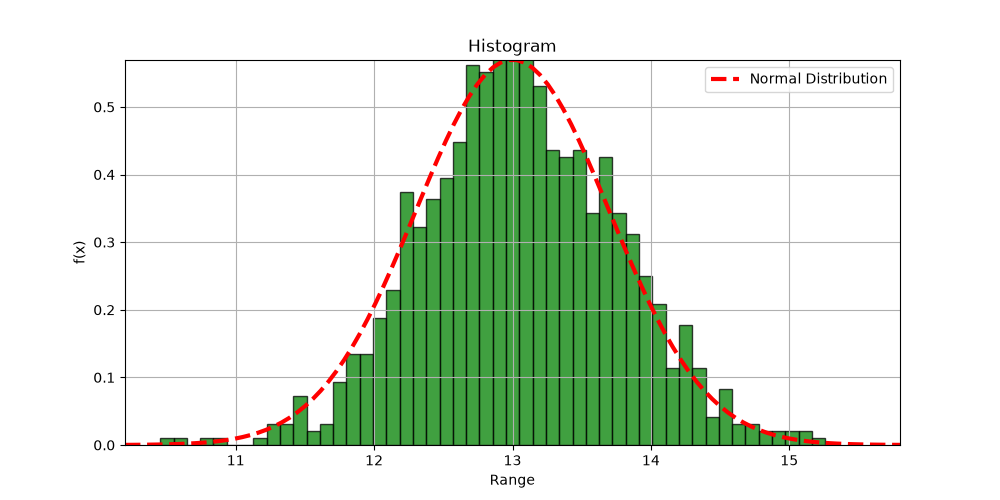

In [1]:
import sys
from pathlib import Path
sys.path.append(str(Path.cwd().parent))
from statistic import *
%matplotlib widget
############## input data #################
modeledTemp   = 13 # deg
nMeasurements   = 1000
oneSigma        = 0.7 # deg
sistematicError =  0 # deg
whiteNoise      =  0 # deg
##########################################

plot_measurement_model(nMeasurements, sistematicError, modeledTemp, oneSigma, whiteNoise)

## Markov Process

A **Markov process** is a mathematical system that evolves in time in such a way that the future state of the system depends only on its current state, not on its past states. This property is called the **Markov property**.


### Random Walk

A particularly interesting  example the Markov precesses is the **random walk**, which describes a path consisting of a succession of random steps. An elementary example is the random walk on integer numbers, where the next position equal to  the previous one plus a step in the up, down, left or right direction (which have the same probability to happen):

$$x_{k+1}=x_{k} + \Delta $$

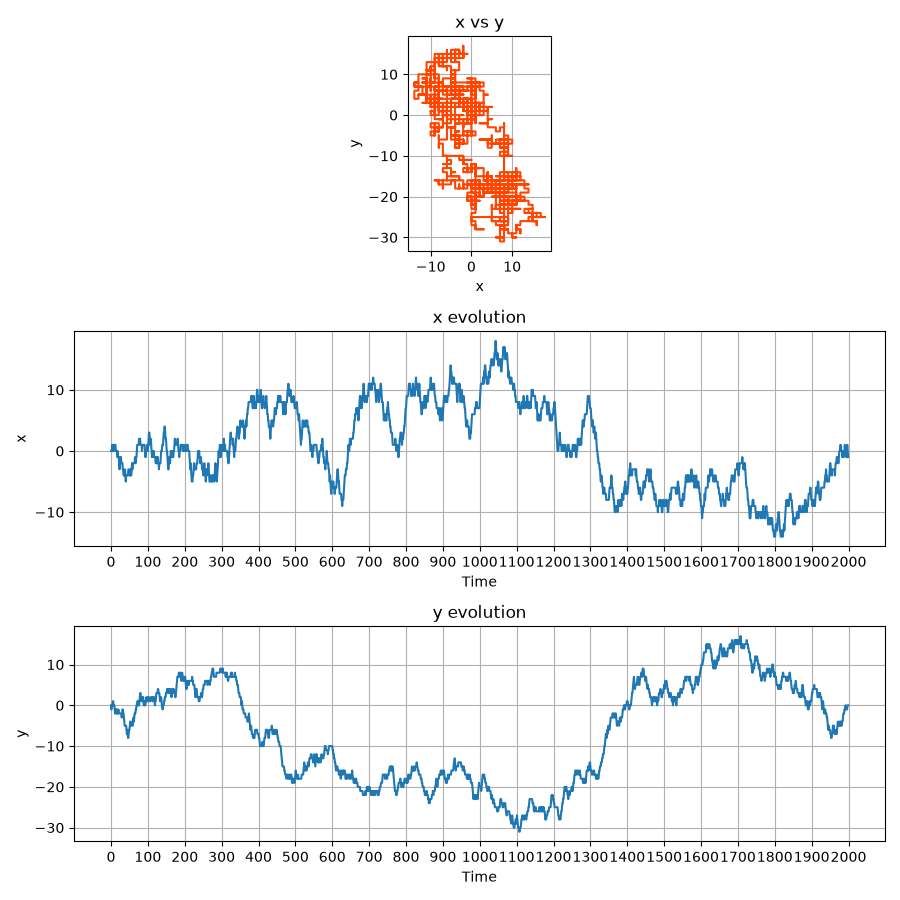

In [2]:
nSteps = 2000
randomSeed = 23

plot_random_walk(nSteps, randomSeed)

## Gauss-Markov Process
A Gauss-Markov process is a stochastic process that combines the properties of a Gaussian process and a Markov process. In other words, it is a process in which any finite set of random variables has a joint Gaussian distribution, and the future of the process depends only on its present state (and not on its past).



### Brownian Motion

A particularly important example of a Gaussian stochastic process is **Brownian motion**, also known as the Wiener process. This is a time-dependent process where the increments over $\Delta t$ are due to a normally distributed stochastic variable $q_k$ with zero mean and standard deviation equal to $\sqrt \Delta t$:

$$x_{k+1}=x_{k} + q_k $$

The increments are independent and normally distributed. Brownian motion is used to model a wide range of phenomena, including the movement of particles in a fluid and the fluctuations of stock prices.



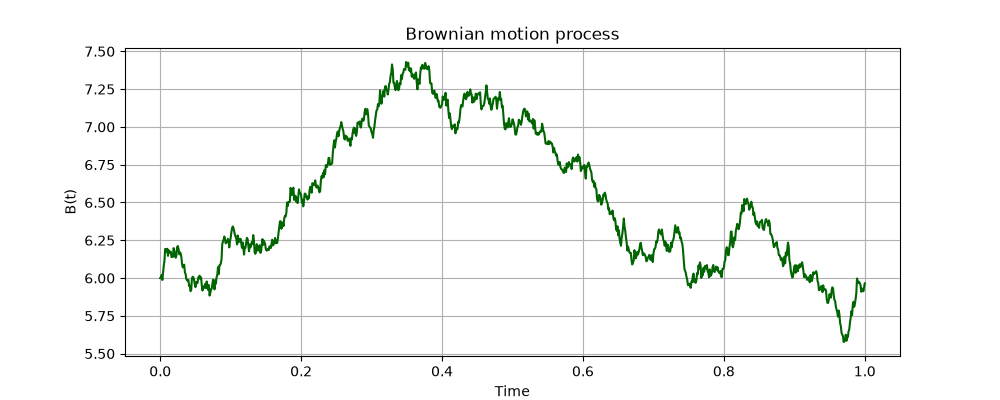

In [4]:
######## Input parameters #########
initValue = 6
T = 1.0  # duration
N = 1000  # Number of steps
###################################

plot_brownian_motion(initValue, T, N)

### Exponentially Decaying Process

This process is used in orbit determination to model for how long the filter's correction of a state variable should be considered in absence of new measurements:


$$  x_{k+1}=x_k e^{-\left ( t_{k+1} - t_k\right )/\tau} +q_k \sqrt{1-e^{-2\left ( t_{k+1} - t_k\right )/\tau}}$$

, where:
- $q_k$ is a normally distributed stochastic value with zero mean and standard deviation equal to $\sigma$
- $\tau$ is the **time constant** of the process: in absence of noise, after a time $\tau$ the initial value is reduced to $1/e \approx 37\%$ of itself (the half life is $\tau \ln 2$)

By manipulating $\tau$ you can:

- Force serial correlation with a very high $\tau$ (e.g., 500000)
- Force white noise with a very small $\tau$ (e.g., 0.000001)

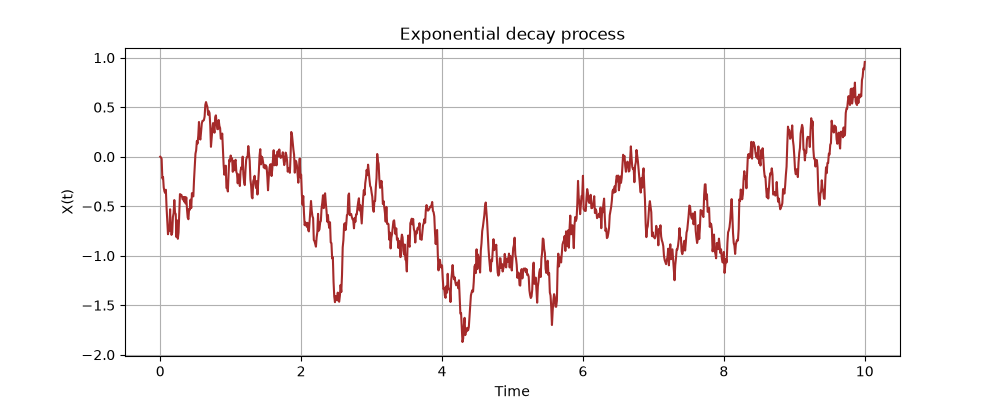

In [5]:
######## Input parameters #########
initValue = 0
T = 10    # duration
N = 1000  # Number of steps
tau = 1 #  time constant
sigma = 1 # standard deviation
###################################

plot_exponential_decay(initValue, T, N, tau, sigma)

## Stochastic Model Derivation for Measurement Devices

Measurement devices are not perfect in nature: they always introduce an error which deviates the measurements from the truth. Each measurement brings with it an error which is unknown for each individual one but can instead be modeled using a specific stochastic process. Measurement errors belong to the following categories:

- **Random errors**: Non-deterministic errors which can be described by a stochastic process. On average, the random errors will be zero
- **Systematic bias**: Deterministic errors which affects all or a subset of the measurements. Systematic biases may result in a constant offset in all measurements, but may also change in time. Systematic biases can be caused for instance due to malfunctioning or wrong usage of the instrument
- **Outliers**: Non-deterministic errors in one of the measurements, also referred to as blunder or spurious error

Also, we need to consider the **white noise**, which is a discrete signal whose samples are regarded as a sequence of serially uncorrelated random variables with zero mean and finite variance. It is related to the thermal effects in an electrical circuits, and is an unavoidable effect present in any measurement device.

### Quality of the Observations

The quality of the observations is described by the precision and accuracy:

- **Precision**: how close repeated measurements are to each other, i.e. how much repeated measurements fluctuate around their mean. The parameter to consider to evaluate the precision is the standard deviation
-  **Accuracy**: how close the result is to the true value. In this case, the systematic bias is the parameter to consider

### Random Errors

Accordingly with the central limit theorem, which states that a large number of individual measurements having independent errors will converge to a normal (Gaussian) distribution, we can estimate the true value by deriving the mean $\mu$ and the error dispersion by deriving the standard deviation $\sigma$, which is defined as

$$\sigma = \sqrt{\frac{1}{m} \sum_{i=1}^{m} \left ( y_{i} - \mu \right )^{2}} $$

In absence of systematic biases and outliers, the individual random errors are the deviations of repeated measurements from their mean:

$$e_i = y_i-\mu$$

Note as random errors are usually assumed to have a normal distribution with zero mean.

### Residuals and Root Mean Square Error

State evolution models provide expected values for any time instant. We can compare the measurement value at time $i$ with the modeled value at the same time. We define the **residuals** as the difference between measured values and model's values:

$$r_i = y_i - \hat{y}_i$$

Accordingly, we define the **Root Mean Square Error (RMSE)** as the difference between the observed and modeled values:

$$RMSE = \sqrt{\frac{1}{m} \sum_{i=1}^{m} \left ( y_{i} - \hat{y}_i \right )^{2}} $$

The main difference between $\sigma$ and the RMSE is whether we are considering the deviation of the estimator of interest from the 'true' parameter (RMSE), or the deviation of the estimator from its mean ($\sigma$); consequently, we can see that when the bias of the estimator is zero, the standard deviation and the RMSE are equal. 

In other words, <u> the standard deviation just measures the dispersion of the values; the RMSE indicates how different the values of the estimator and the actual values of the parameters are</u>. 

From the values of the residuals we can also estimate their standard deviation, estimating the performances of the tracking device.